In [1]:
import os
import numpy as npx
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
path = r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\output.csv"
df = pd.read_csv(path)
col_groups = {
    # "ORR": ["Redox"],
    "CAR" :[
        "CAR 18:2 (+H)",
        "CAR 18:1 (+H)",
        "CAR 18:0 (+H)"
    ],
    "CL" : [
        "CL 72:8 (-H)", #1447.965 CL 72:8 (-H),
        "CL 74:11 (-H)",# 1469.9493 CL 74:11 (-H)
    ],
    "LPL" : [
        "LPC 16:0 (+H)",
        "LPE 18:0 (-H)",
        "LPI 18:0 (-H)",
    ],
    "PL (Sat)" :[
        "PC 32:0 (+H)",
        "PE 16:0_18:0 (-H)",
        "PI 16:0_18:0 (-H)",
    ],
    "PL (MUFA)":[
        "PC 16:0_18:1 (+H)",
        "PC 18:0_18:1 (+H)",
        "PA 36:1 (-H)",
        "PS 18:0_18:1 (-H)",
        "PI 34:1 (-H)",
        "PI 18:0_18:1 (-H)",   
    ] ,
    "PL (AA)":[
        "PE 16:0_20:4 (-H)",
        "PE 18:1_20:4 (-H)",
        "PE 18:1_20:3 (-H)",
        "PS 16:0_20:4 (-H)",
        "PS 18:0_20:4 (-H)",
        "PI 16:0_20:4 (-H)",
        "PI 18:1_20:3 (-H)",
        "PC 35:4 (+H)",
        "PC 36:5 (+H)",
        "PC 18:0_20:4 (+H)",
    ],
    "PL (DHA)":[
        "PE 16:0_22:6 (-H)",
        "PG 18:1_22:6 (-H)",
    ],
    "PL (PUFA)":[
        "PC O-38:5 (+H)",
        "PC 38:5 (+H)",
        "PC 46:9 (-CH3)",
        "PE 49:9 (-H)",
        "PC 48:9 (-CH3)",
    ],

    "SM":[
        "SM 34:1;2O (+H)",
        "SM 38:1;20 (+H)",
        "SM 42:2;2O (+H)",
        "SM 42:1;2O (+H)",
        "SM 41:0;3O (+H)",
        "SM 42:0;3O (+H)",
        "SM 18:1;2O/16:0 (-CH3)"
    ],
    "SHexCer" : [
        "SHexCer 40:1;3O (-H)",
        "SHexCer 41:1;3O (-H)",
        "SHexCer 42:2;3O (-H)",
        "SHexCer 42:1;3O (-H)",
        "SHexCer 42:0;3O (-H)",
        "SHexCer 50:0;2O (-H)"
    ],
        "Lipid Unsat.": ["Lipid_Unsaturation"],
        "Lipid/Protein" : ["Lipid_to_Protein"],

    "Fib. Collagen": [
        # 'Collagen',
        "Collagen_Thickness",
        "Collagen_Coherence"
    ],

}
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# df = df[df['Source_ID']=='S21']

# df = df[df['tissue_id']=='S21-K21_198_3']

for new_col, source_cols in col_groups.items():
    df[new_col] = df[source_cols].mean(axis=1)

unit_order = [
      "Cluster1",
      "Cluster2",
      "Cluster4",
      "Cluster5",
      "Cluster6",
      "Cluster7",
      "Cluster8",
      "Cluster9",
    #   "Cluster10",
      "Cluster11",
      "Cluster12",
      "Cluster15",
      "Cluster16",
      "Cluster17",
      "Cluster18",
      "Cluster19",
      "Cluster20",
      "Cluster21",
      "Cluster22",
      "Cluster23",
      "Cluster24",
      "Cluster25",
      "Cluster26"
    ]
# group_order = ['OC', 'IC', 'CM', 'OS', "IS"]

group_order = [
    'Outer Cortex', 
    'Middle Cortex', 
    'Juxtamedullary Cortex', 
    'Outer Stripe', 
    'Inner Stripe',
    'Inner Medulla'
    ]

# group_map ={
#     'C1': 'Outer Cortex',
#     'C2': 'Inner Cortex',
#     'C3': 'CM Boundary',
#     'CM': 'Outer Stripe',
#     'M': 'Inner Stripe'
# }

# df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)
for i, val_col in enumerate(df.columns[7:]):
    df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name'])[val_col].transform('median'))

df[df.columns[7:]] = df[df.columns[7:]].fillna(0)

# df['Group_ID'] = df['Group_ID'].map(group_map)
# df.drop(columns=['Redox', 'Collagen_Coherence', 'Collagen_Thickness'],inplace=True)

df = df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )

C:\Users\jvill\AppData\Local\Temp\ipykernel_9684\2813773976.py:140: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name'])[val_col].transform('median'))
C:\Users\jvill\AppData\Local\Temp\ipykernel_9684\2813773976.py:140: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df[val_col] = df[val_col].fillna(df.groupby(['group', 'mask_name'])[val_col].transform('median'))
C:\Users\jvill\AppData\Local\Temp\ipykernel_9684\2813773976.py:140: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass o

In [7]:
df

,tissue_id,group,unit,condition,mask_name,centroid_y,centroid_x,CAR 18:0 (+H),CAR 18:1 (+H),CAR 18:2 (+H),...,PL (Sat),PL (MUFA),PL (AA),PL (DHA),PL (PUFA),SM,SHexCer,Lipid Unsat.,Lipid/Protein,Fib. Collagen
0,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1690,8410,10.557900,32.015504,25.345572,...,47.441176,67.632353,33.387319,6.383041,33.527629,41.641711,26.973262,0.482838,0.289949,1.114638
1,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1738,7942,10.557900,32.015504,25.345572,...,33.805000,53.762500,45.456429,9.432885,97.251667,8.380000,82.660833,0.426448,0.304299,0.983739
2,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1785,7030,10.557900,32.015504,25.345572,...,53.143868,40.408019,26.845962,10.248920,30.886792,93.570755,19.253145,0.438729,0.341586,1.086228
3,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1806,8175,10.557900,32.015504,25.345572,...,42.306452,34.461022,18.386806,16.018817,38.777778,49.500000,28.550179,0.493299,0.332135,1.030810
4,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1920,8664,10.557900,32.015504,25.345572,...,32.941379,50.056034,46.625063,20.159124,95.868966,9.868966,54.983333,0.445977,0.325758,0.880198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175523,S24-K21_273_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,7063,16977,12.400000,39.711111,31.272222,...,118.050000,69.272222,13.986462,13.071160,28.381117,12.658493,12.390773,0.458232,0.333845,3.051164
175524,S24-K21_273_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,7147,16702,14.594805,29.296104,48.189610,...,96.018182,75.836364,19.350649,13.071160,19.942796,13.584830,12.390773,0.487741,0.357218,2.048281
175525,S24-K21_273_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,7152,16682,8.030000,27.625000,35.885000,...,88.770000,76.130000,21.899058,13.071160,25.547500,15.161909,12.390773,0.444585,0.336211,1.687691
175526,S24-K21_273_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,7171,16649,12.328947,26.140351,28.263158,...,105.241228,80.835526,23.555556,13.071160,22.278509,18.130848,12.390773,0.469030,0.349924,1.676772


## UMAP

In [ ]:
# import umap 

# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler().set_output(transform="pandas")
# umap_df = df.copy()
# umap_df[df.columns[7:-13]] = scaler.fit_transform(df[df.columns[7:-13]])
# # umap_df = umap_df.dropna()
# reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# embedding = reducer.fit_transform(umap_df[df.columns[7:-13]])

# umap_df['umap_1'] = embedding[:, 0]
# umap_df['umap_2'] = embedding[:, 1]
        

ModuleNotFoundError: No module named 'umap'

In [ ]:
# import umap 
# umap_df = df.copy()

# # feature_cols = df.columns[7:-13]

# # q1 = df.groupby('mask_name')[feature_cols].transform('quantile', 0.25)
# # q3 = df.groupby('mask_name')[feature_cols].transform('quantile', 0.75)
# # iqr = q3 - q1

# # # 2. Define outlier boundaries (1.5 * IQR rule)
# # lower_bound = q1 - 1.5 * iqr
# # upper_bound = q3 + 1.5 * iqr

# # # 3. Create a mask where rows must be within bounds for ALL features
# # # True if feature is within group bounds, False if it is an outlier
# # within_bounds = (df[feature_cols] >= lower_bound) & (df[feature_cols] <= upper_bound)

# # # Keep rows where NO feature is an outlier
# # clean_df = df[within_bounds.all(axis=1)].copy()

# # # 4. Separate features and scale/run UMAP on the cleaned data
# # umap_df = clean_df


# umap_df[df.columns[7:-13]] = umap_df.groupby('tissue_id')[df.columns[7:-13]].transform(lambda x: (x - x.mean()) / x.std())
# # umap_df = umap_df.dropna()
# reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# embedding = reducer.fit_transform(umap_df[df.columns[7:-13]])

# umap_df['umap_1'] = embedding[:, 0]
# umap_df['umap_2'] = embedding[:, 1]

c:\Users\jvill\miniconda3\envs\hsi_machine_learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\jvill\miniconda3\envs\hsi_machine_learning\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


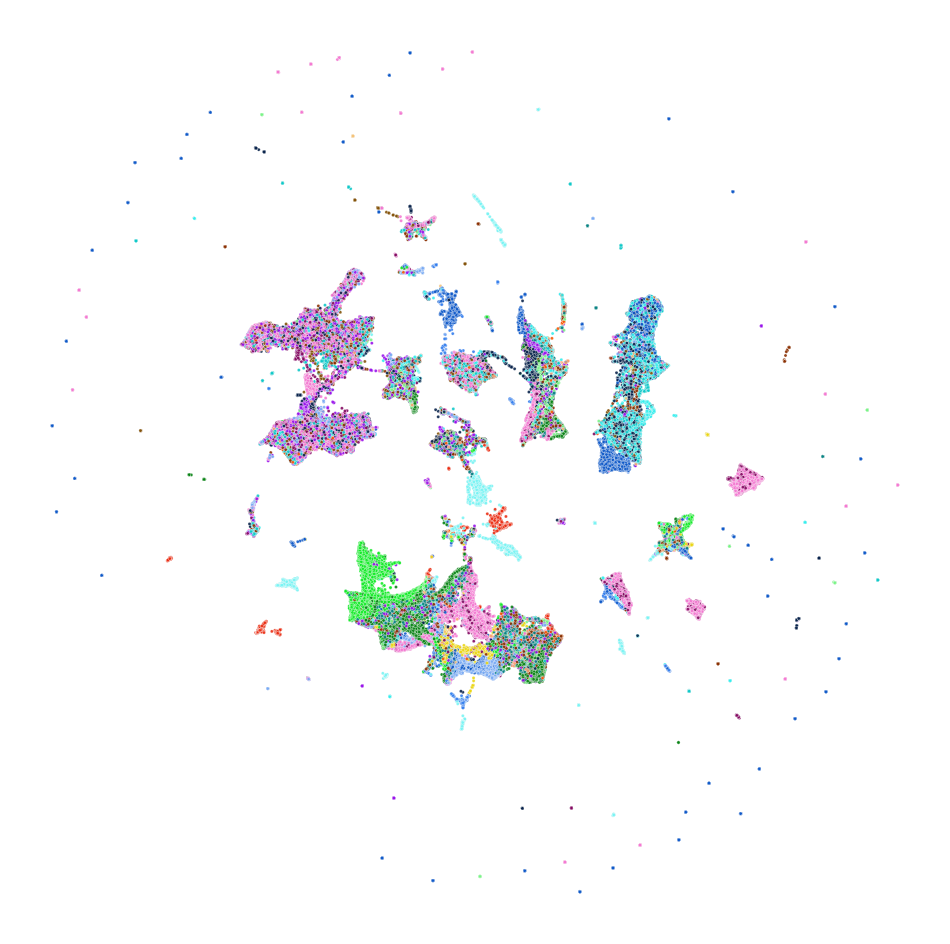

In [ ]:
import matplotlib.patheffects as pe
import numpy as np
fig, ax = plt.subplots(figsize=(12, 12))


"""Keep this cell to load and remap saved umap csv for plotting"""
# umap_df = pd.read_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv")
# # umap_df = df.copy()
# umap_df2 = umap_df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )
hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    # "Cluster3": "#42a84c",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62", 
    "Cluster9": "#f47ad2",
    # "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#09234b",
    # "Cluster13": "#0a3b84",
    # "Cluster14": "#355483",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#ffede4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }


umap_df = umap_df2.sample(frac=1, random_state=42)
sns.scatterplot(
    data=umap_df,
    x='umap_1', y='umap_2',
    hue='mask_name',
    palette=hue_colors,
    # hue_order=hue_order_display,
    alpha=0.9,
    edgecolor='w',
    linewidth=0.2,
    s=5,
    ax=ax
)
embeddings = umap_df[["umap_1", "umap_2"]].values
labels = umap_df["group"].values
unique_labels = umap_df["group"].unique()

# 5. Place clean, bold labels at each cluster's median centroid
# for label in unique_labels:
#     mask = labels == label
#     # Using median for both coordinates yields a better geometric center
#     centroid_x = np.median(embeddings[mask, 0])
#     centroid_y = np.median(embeddings[mask, 1])

#     ax.text(
#         centroid_x,
#         centroid_y,
#         label,
#         fontsize=12,  # Adjusted to fit 6x6 figure nicely
#         fontweight="bold",
#         ha="center",
#         va="center",
#         color="black",
#         rotation=90,
#         path_effects=[pe.withStroke(linewidth=3, foreground="white")],
#         zorder=100,
#     )
# Formatting axes
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels([])
ax.set_yticklabels([])
sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
ax.tick_params(left=False, bottom=False)

# Remove the default legend (since we have text labels on centroids)
legend = ax.get_legend()
if legend is not None:
    legend.remove()
plt.savefig(os.path.join(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks", "lipids-nomid-clusters-UMAP.png"), dpi=300, transparent=True)

In [38]:
umap_df2.to_csv(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv-test\umap-nomid-output.csv", index=False)

## Region Gradients

In [ ]:
# path = r"E:\integrated_pipeline\WSI_data\WSI_data\CODEX_clusters-regions_masks_output_csv\masked_ratio_means-wide.csv"
# df = pd.read_csv(path)
# col_groups = {
#     "ORR": ["Redox"],
#     "CAR" :[
#         "Positive_Ion_3",
#         "Positive_Ion_4",
#         "Positive_Ion_5"
#     ],
#     "CL" : [
#         "Negative_Ion_33", #1447.965 CL 72:8 (-H),
#         "Negative_Ion_34",# 1469.9493 CL 74:11 (-H)
#     ],
#     "LPL" : [
#         "Negative_Ion_1",
#         "Negative_Ion_3",
#         "Positive_Ion_7",
#     ],
#     "PL (Sat)" :[
#         "Positive_Ion_11",
#         "Negative_Ion_7",
#         "Negative_Ion_18",
#     ],
#     "PL (MUFA)":[
#         "Positive_Ion_14",
#         "Positive_Ion_18",
#         "Negative_Ion_5",
#         "Negative_Ion_17",
#         "Negative_Ion_21",   
#     ] ,
#     "PL (AA)":[
#         "Negative_Ion_8",
#         "Negative_Ion_10",
#         "Negative_Ion_11",
#         "Negative_Ion_12",
#         "Negative_Ion_14",
#         "Negative_Ion_19",
#         "Negative_Ion_23",
#         "Positive_Ion_15",
#         "Positive_Ion_16",
#         "Positive_Ion_21",
#     ],
#     "PL (DHA)":[
#         "Negative_Ion_9",
#         "Negative_Ion_15",
#     ],
#     "PL (PUFA)":[
#         "Positive_Ion_19",
#         "Positive_Ion_20",
#         "Negative_Ion_26",
#         "Negative_Ion_30",
#         "Negative_Ion_31",
#     ],
#     "Lipid Unsat.": ["Lipid_Unsaturation"],
#     "SM":[
#         "Positive_Ion_9",
#         "Positive_Ion_13",
#         "Positive_Ion_22",
#         "Positive_Ion_23",
#         "Positive_Ion_24",
#         "Positive_Ion_25",
#         "Negative_Ion_4"
#     ],
#             "SHexCer" : [
#         "Negative_Ion_22",
#         "Negative_Ion_24",
#         "Negative_Ion_27",
#         "Negative_Ion_28",
#         "Negative_Ion_29",
#         "Negative_Ion_32"
#     ],

#         "Fib. Collagen": [
#         'Collagen',
#         "Collagen_Thickness",
#         "Collagen_Coherence"
#     ],

# }
# if 'Unnamed: 0' in df.columns:
#     df = df.drop(columns=['Unnamed: 0'])

# df = df[df['Source_ID']=='S21']

# for new_col, source_cols in col_groups.items():
#     df[new_col] = df[source_cols].mean(axis=1)

# unit_order = [
#       "Cluster1",
#       "Cluster2",
#       "Cluster4",
#       "Cluster5",
#       "Cluster6",
#       "Cluster7",
#       "Cluster9",
#       "Cluster10",
#       "Cluster11",
#       "Cluster13",
#       "Cluster15",
#       "Cluster16",
#       "Cluster17",
#       "Cluster18",
#       "Cluster19",
#       "Cluster20",
#       "Cluster21",
#       "Cluster23",
#       "Cluster24",
#       "Cluster25",
#       "Cluster26"
#     ]
# # group_order = ['OC', 'IC', 'CM', 'OS', "IS"]

# group_order = ['C1', 'C2', 'C3', 'CM', 'M']
# df['Unit'] = pd.Categorical(df['Unit'], categories=unit_order, ordered=True)
# df['Group_ID'] = pd.Categorical(df['Group_ID'], categories=group_order, ordered=True)

In [ ]:
# import numpy as np

# group_order = ['C1', 'C2', 'C3', 'CM', 'M']
# df['Unit'] = pd.Categorical(df['Unit'], categories=unit_order, ordered=True)
# df['Group_ID'] = pd.Categorical(df['Group_ID'], categories=group_order, ordered=True)

# hue_colors={
#     "Cluster1": "#eb2d13",
#     "Cluster2": "#0a8416",
#     "Cluster4": "#13eb28",
#     "Cluster5": "#7af487",
#     "Cluster6": "#84530a",
#     "Cluster7": "#f4c37a",
#     "Cluster9": "#840a62",
#     "Cluster10": "#f47ad2",
#     "Cluster11": "#ebd613",
#     "Cluster13": "#0a3b84",
#     "Cluster15": "#105ac9",
#     "Cluster16": "#357fee",
#     "Cluster17": "#7aabf4",
#     "Cluster18": "#0a8484",
#     "Cluster19": "#10c9c9",
#     "Cluster20": "#35eeee",
#     "Cluster21": "#7af4f4",
#     "Cluster23": "#8b3103",
#     "Cluster24": "#f85706",
#     "Cluster25": "#fba173",
#     "Cluster26": "#9913eb"
#   }

# fig, ax = plt.subplots(figsize=(2.25*len(col_groups.keys()), 6), ncols=len(col_groups.keys()), nrows=1, sharey=True)

# regions = ['Outer\nCortex', 'Inner\nCortex', 'CM\nBoundary', 'Outer\nStripe', 'Inner\nStripe']
# for i, val_col in enumerate(col_groups.keys()):
#     item_data_plot = df[['Unit', 'Group_ID', val_col]].replace([np.inf, -np.inf], np.nan).dropna(subset=[val_col]).copy()
#     agg_data_plot = item_data_plot.groupby(['Group_ID', 'Unit'])[val_col].agg(['mean', 'count']).reset_index()
#     agg_data_plot['unit_total']= agg_data_plot.groupby('Unit')['count'].transform('sum')
#     agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
#     pivot_df = agg_data_plot.pivot(index='Group_ID', columns='Unit', values='mean')

#     z_df = pivot_df.copy().astype(float)
#     z_values = z_df.to_numpy(dtype=float)
#     z_mean = np.nanmean(z_values)
#     z_std = np.nanstd(z_values)
#     if np.isnan(z_std) or z_std == 0:
#         z_df = z_df - z_mean
#     else:
#         z_df = (z_df - z_mean) / z_std

#     item_abs_max = np.nanmax(np.abs(z_df.to_numpy(dtype=float)))
#     if np.isnan(item_abs_max):
#         item_abs_max = 0

#     inverted_df = z_df.iloc[::-1, ::-1]
#     inverted_df.plot(ax=ax[i], kind='barh', xlabel=val_col, width=0.9, color=list(hue_colors.values())[::-1]) 
#     # ax[i].set_yticklabels(group_order[::-1],fontsize=14, fontweight='bold')


#     ax[i].axvline(0, color='lightgray', linestyle='--')
#     ax[i].get_legend().remove() 


#     y_ticks = ax[i].get_yticks()

#     if i == 0:
#         sns.despine(ax=ax[i], top=True, right=True, left=False)
#     elif i == len(col_groups.keys()):
#         sns.despine(ax=ax[i], top=True, right=False, left=True)
#     else:
#         sns.despine(ax=ax[i], top=True, right=True, left=True)

#     if len(y_ticks) > 1:
#         # Calculate the distance between bars
#         spacing = y_ticks[1] - y_ticks[0]
        
#         # This includes boundary lines below the first bar and above the last bar
#         minor_ticks = np.arange(y_ticks[0] - spacing/2, y_ticks[-1] + spacing, spacing)
#         ax[i].set_yticks(minor_ticks, minor=True)
        
#         # Turn off the major grid (at the ticks) and turn on the minor grid
#         ax[i].grid(False, which='major', axis='y')
#         ax[i].grid(True, which='minor', axis='y', linestyle='-.', color='gray', linewidth=0.9)
        
#     # ax[i].set_xlim(-2, 2)


#     ax[i].tick_params(which='both', axis='y', length=0)
#     ax[i].tick_params(axis='x', labelsize=14)
#     ax[i].set_yticklabels(regions[::-1], fontsize=20, fontweight='bold')
#     ax[i].set_ylabel('')
#     ax[i].set_xlabel('')
#     ax[i].set_title(val_col.replace(" ",'\n'), y=1.04, va='center', fontsize=18, fontweight='bold')

#     # ax[i].xaxis.label.set(fontsize=18, fontweight='bold')
# plt.tight_layout()
# plt.savefig(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks\region_gradient_barplot.png",dpi=300, transparent=True)
plt.show()

C:\Users\jvill\AppData\Local\Temp\ipykernel_36940\3998383470.py:44: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
C:\Users\jvill\AppData\Local\Temp\ipykernel_36940\3998383470.py:45: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
C:\Users\jvill\AppData\Local\Temp\ipykernel_36940\3998383470.py:44: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pas

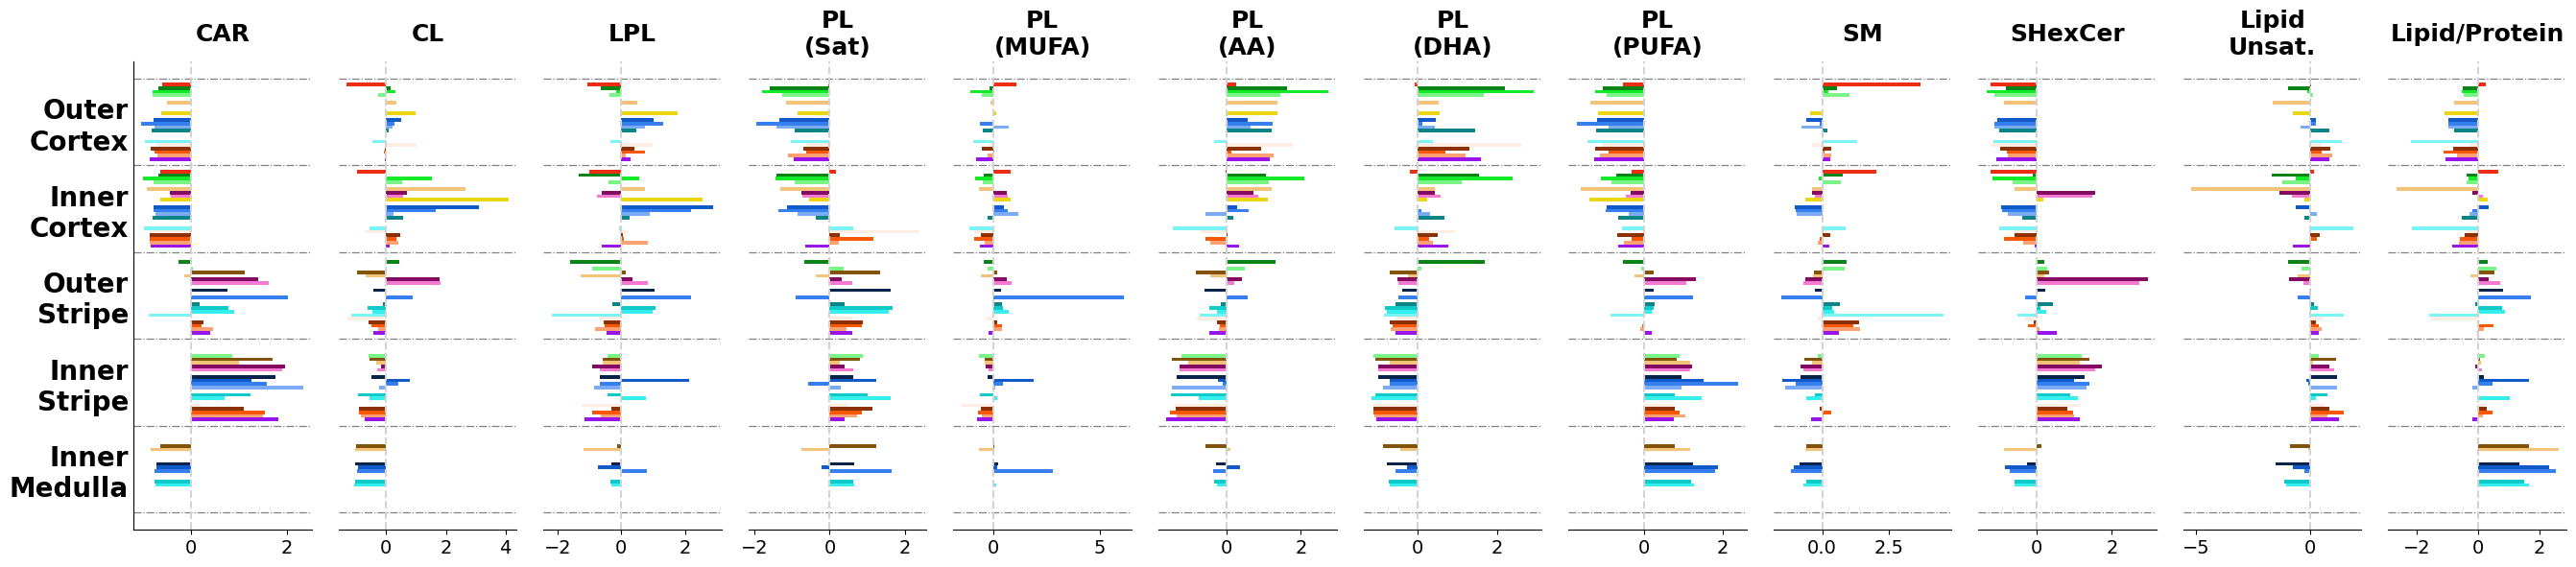

In [36]:
df = df.replace({'Middle Cortex': 'Outer Cortex', 'Juxtamedullary Cortex': 'Inner Cortex', 'Cluster3':'Cluster4', 'Cluster13': 'Cluster12', 'Cluster14': 'Cluster12', 'Cluster10': 'Cluster9'} )

group_order = ['Outer Cortex', 'Inner Cortex', 'Outer Stripe', 'Inner Stripe', 'Inner Medulla']

regions = ['Outer\nCortex', 'Inner\nCortex', 'Outer\nStripe', 'Inner\nStripe', 'Inner\nMedulla']

df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    # "Cluster3": "#42a84c",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster8": "#840a62", 
    "Cluster9": "#f47ad2",
    # "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster12": "#09234b",
    # "Cluster13": "#0a3b84",
    # "Cluster14": "#355483",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster22": "#ffede4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }

fig, ax = plt.subplots(figsize=(2.25*len(col_groups.keys()), 6), ncols=len(col_groups.keys()), nrows=1, sharey=True)

# regions = ['Outer\nCortex', 'Inner\nCortex', 'CM\nBoundary', 'Outer\nStripe', 'Inner\nStripe']
for i, val_col in enumerate(col_groups.keys()):
    item_data_plot = df[['mask_name', 'group', val_col]].replace([np.inf, -np.inf], np.nan).dropna(subset=[val_col]).copy()
    agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
    agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
    agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
    pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')

    z_df = pivot_df.copy().astype(float)
    z_values = z_df.to_numpy(dtype=float)
    z_mean = np.nanmean(z_values)
    z_std = np.nanstd(z_values)
    if np.isnan(z_std) or z_std == 0:
        z_df = z_df - z_mean
    else:
        z_df = (z_df - z_mean) / z_std

    item_abs_max = np.nanmax(np.abs(z_df.to_numpy(dtype=float)))
    if np.isnan(item_abs_max):
        item_abs_max = 0

    inverted_df = z_df.iloc[::-1, ::-1]
    inverted_df.plot(ax=ax[i], kind='barh', xlabel=val_col, width=0.9, color=list(hue_colors.values())[::-1]) 
    # ax[i].set_yticklabels(group_order[::-1],fontsize=14, fontweight='bold')


    ax[i].axvline(0, color='lightgray', linestyle='--')
    ax[i].get_legend().remove() 


    y_ticks = ax[i].get_yticks()

    if i == 0:
        sns.despine(ax=ax[i], top=True, right=True, left=False)
    elif i == len(col_groups.keys()):
        sns.despine(ax=ax[i], top=True, right=False, left=True)
    else:
        sns.despine(ax=ax[i], top=True, right=True, left=True)

    if len(y_ticks) > 1:
        # Calculate the distance between bars
        spacing = y_ticks[1] - y_ticks[0]
        
        # This includes boundary lines below the first bar and above the last bar
        minor_ticks = np.arange(y_ticks[0] - spacing/2, y_ticks[-1] + spacing, spacing)
        ax[i].set_yticks(minor_ticks, minor=True)
        
        # Turn off the major grid (at the ticks) and turn on the minor grid
        ax[i].grid(False, which='major', axis='y')
        ax[i].grid(True, which='minor', axis='y', linestyle='-.', color='gray', linewidth=0.9)
        
    # ax[i].set_xlim(-2, 2)


    ax[i].tick_params(which='both', axis='y', length=0)
    ax[i].tick_params(axis='x', labelsize=14)
    ax[i].set_yticklabels(regions[::-1], fontsize=20, fontweight='bold')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title(val_col.replace(" ",'\n'), y=1.04, va='center', fontsize=18, fontweight='bold')

    # ax[i].xaxis.label.set(fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks\region_gradient_barplot.png",dpi=300, transparent=True)
plt.show()

In [48]:
item_data_plot = df[['mask_name', 'group', 'Lipid Unsat.']].replace([np.inf, -np.inf], np.nan).dropna(subset=['Lipid Unsat.']).copy()
agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])['Lipid Unsat.'].agg(['mean', 'std', 'count']).reset_index()
agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')
unit_data_plot = agg_data_plot[agg_data_plot['mask_name'].isin(['Cluster2', 'Cluster4', 'Cluster5'])]

C:\Users\jvill\AppData\Local\Temp\ipykernel_36940\3866993522.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])['Lipid Unsat.'].agg(['mean', 'std', 'count']).reset_index()
C:\Users\jvill\AppData\Local\Temp\ipykernel_36940\3866993522.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')


C:\Users\jvill\AppData\Local\Temp\ipykernel_5420\2100913164.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
C:\Users\jvill\AppData\Local\Temp\ipykernel_5420\2100913164.py:37: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
C:\Users\jvill\AppData\Local\Temp\ipykernel_5420\2100913164.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass o

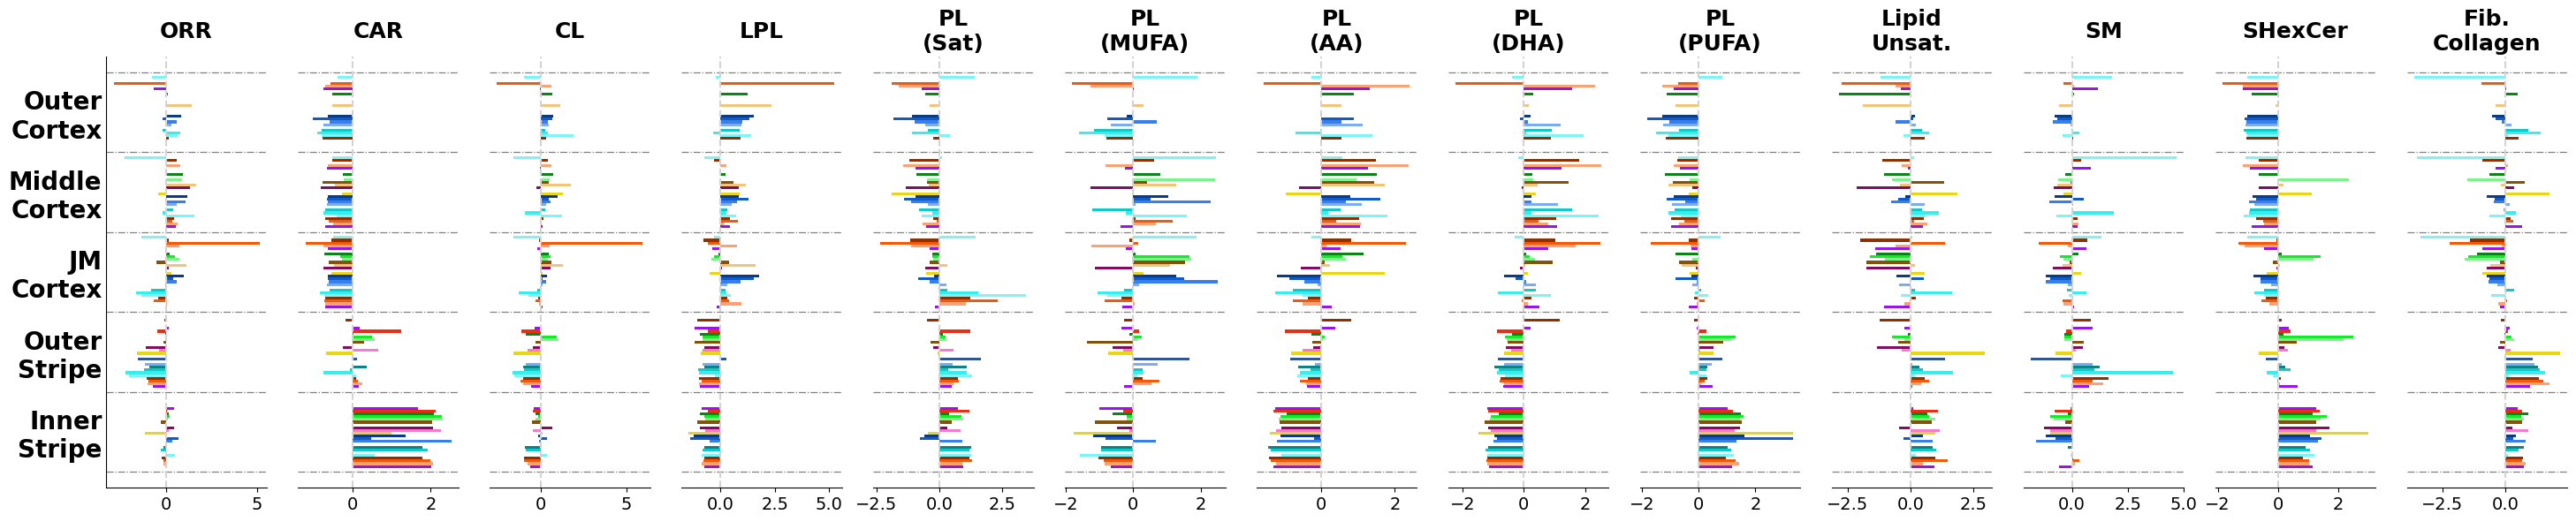

In [ ]:
import numpy as np

# group_order = ['C1', 'C2', 'C3', 'CM', 'M']
# df['mask_name'] = pd.Categorical(df['mask_name'], categories=unit_order, ordered=True)
# df['group'] = pd.Categorical(df['group'], categories=group_order, ordered=True)

hue_colors={
    "Cluster1": "#eb2d13",
    "Cluster2": "#0a8416",
    "Cluster4": "#13eb28",
    "Cluster5": "#7af487",
    "Cluster6": "#84530a",
    "Cluster7": "#f4c37a",
    "Cluster9": "#840a62",
    "Cluster10": "#f47ad2",
    "Cluster11": "#ebd613",
    "Cluster13": "#0a3b84",
    "Cluster15": "#105ac9",
    "Cluster16": "#357fee",
    "Cluster17": "#7aabf4",
    "Cluster18": "#0a8484",
    "Cluster19": "#10c9c9",
    "Cluster20": "#35eeee",
    "Cluster21": "#7af4f4",
    "Cluster23": "#8b3103",
    "Cluster24": "#f85706",
    "Cluster25": "#fba173",
    "Cluster26": "#9913eb"
  }

fig, ax = plt.subplots(figsize=(2.25*len(col_groups.keys()), 6), ncols=len(col_groups.keys()), nrows=1, sharey=True)

regions = ['Outer\nCortex', 'Middle\nCortex', 'JM\nCortex', 'Outer\nStripe', 'Inner\nStripe']
for i, val_col in enumerate(col_groups.keys()):
    item_data_plot = df[['mask_name', 'group', val_col]].replace([np.inf, -np.inf], np.nan).dropna(subset=[val_col]).copy()
    agg_data_plot = item_data_plot.groupby(['group', 'mask_name'])[val_col].agg(['mean', 'count']).reset_index()
    agg_data_plot['unit_total']= agg_data_plot.groupby('mask_name')['count'].transform('sum')
    agg_data_plot = agg_data_plot[agg_data_plot['count'] / agg_data_plot['unit_total'] >=0.07]
    pivot_df = agg_data_plot.pivot(index='group', columns='mask_name', values='mean')

    z_df = pivot_df.copy().astype(float)
    z_values = z_df.to_numpy(dtype=float)
    z_mean = np.nanmean(z_values)
    z_std = np.nanstd(z_values)
    if np.isnan(z_std) or z_std == 0:
        z_df = z_df - z_mean
    else:
        z_df = (z_df - z_mean) / z_std

    item_abs_max = np.nanmax(np.abs(z_df.to_numpy(dtype=float)))
    if np.isnan(item_abs_max):
        item_abs_max = 0

    inverted_df = z_df.iloc[::-1, ::-1]
    inverted_df.plot(ax=ax[i], kind='barh', xlabel=val_col, width=0.9, color=list(hue_colors.values())[::-1]) 
    # ax[i].set_yticklabels(group_order[::-1],fontsize=14, fontweight='bold')


    ax[i].axvline(0, color='lightgray', linestyle='--')
    ax[i].get_legend().remove() 


    y_ticks = ax[i].get_yticks()

    if i == 0:
        sns.despine(ax=ax[i], top=True, right=True, left=False)
    elif i == len(col_groups.keys()):
        sns.despine(ax=ax[i], top=True, right=False, left=True)
    else:
        sns.despine(ax=ax[i], top=True, right=True, left=True)

    if len(y_ticks) > 1:
        # Calculate the distance between bars
        spacing = y_ticks[1] - y_ticks[0]
        
        # This includes boundary lines below the first bar and above the last bar
        minor_ticks = np.arange(y_ticks[0] - spacing/2, y_ticks[-1] + spacing, spacing)
        ax[i].set_yticks(minor_ticks, minor=True)
        
        # Turn off the major grid (at the ticks) and turn on the minor grid
        ax[i].grid(False, which='major', axis='y')
        ax[i].grid(True, which='minor', axis='y', linestyle='-.', color='gray', linewidth=0.9)
        
    # ax[i].set_xlim(-2, 2)


    ax[i].tick_params(which='both', axis='y', length=0)
    ax[i].tick_params(axis='x', labelsize=14)
    ax[i].set_yticklabels(regions[::-1], fontsize=20, fontweight='bold')
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].set_title(val_col.replace(" ",'\n'), y=1.04, va='center', fontsize=18, fontweight='bold')

    # ax[i].xaxis.label.set(fontsize=18, fontweight='bold')
plt.tight_layout()
# plt.savefig(r"C:\Users\jvill\OneDrive - UC San Diego\integrated_pipeline\WSI_data\WSI_data\plots_CODEX_clusters-regions_masks\region_gradient_barplot.png",dpi=300, transparent=True)
plt.show()

In [34]:
df

,tissue_id,group,unit,condition,mask_name,centroid_y,centroid_x,CAR 18:0 (+H),CAR 18:1 (+H),CAR 18:2 (+H),...,LPL,PL (Sat),PL (MUFA),PL (AA),PL (DHA),PL (PUFA),Lipid Unsat.,SM,SHexCer,Fib. Collagen
0,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1690,8410,50.687147,48.252475,33.559322,...,6.994652,47.441176,67.632353,33.387319,6.383041,33.527629,0.482838,41.641711,26.973262,1.114638
1,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1738,7942,50.687147,48.252475,33.559322,...,6.587500,33.805000,53.762500,45.456429,9.432885,97.251667,0.426448,8.380000,82.660833,0.983739
2,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1785,7030,50.687147,48.252475,33.559322,...,5.811321,53.143868,40.408019,26.845962,10.248920,30.886792,0.438729,93.570755,19.253145,0.960981
3,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1806,8175,50.687147,48.252475,33.559322,...,6.852151,42.306452,34.461022,18.386806,16.018817,38.777778,0.493299,49.500000,28.550179,1.030810
4,S21-K21_198_3,Inner Stripe,DN | Cyto8,Reference,Cluster12,1920,8664,50.687147,48.252475,33.559322,...,10.539655,32.941379,50.056034,46.625063,20.159124,95.868966,0.445977,9.868966,54.983333,0.880198
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117924,S21-K21_198_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,5710,17580,16.785714,8.333333,5.624683,...,22.690476,54.908730,50.188492,36.084843,14.214788,30.045548,0.461918,28.483748,12.461943,0.852623
117925,S21-K21_198_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,6096,16719,17.487805,44.004878,8.180488,...,36.141463,55.121951,68.214634,22.501614,14.214788,33.885366,0.460315,5.033926,12.461943,1.061718
117926,S21-K21_198_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,6139,16539,35.633803,9.577465,11.868545,...,22.403756,48.084507,42.776995,13.417081,14.214788,15.629108,0.486546,11.813594,12.461943,1.542663
117927,S21-K21_198_3,Outer Stripe,VSMCs | aSMA,Reference,Cluster21,6494,16291,4.859551,1.741379,2.661157,...,10.081218,9.380711,17.875635,58.487310,14.214788,73.227406,0.466614,3.288986,12.461943,1.061718
